In [134]:
!pip install -q -U watermark

In [135]:
import sklearn
import xgboost
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

In [136]:
df = pd.read_csv('dataset.csv')


In [137]:
df = df.drop_duplicates().reset_index(drop=True)

In [138]:
df.shape

(302, 14)

In [139]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 302 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.2 KB


In [140]:
### Amostra dos dados
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [141]:
## Verificação de valores ausentes
df.isna().any() 

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
exang       False
oldpeak     False
slope       False
ca          False
thal        False
target      False
dtype: bool

In [142]:
## Há valores ausentes?Quantos?
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [143]:
## Correlação entre as variáveis
df.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.094962,-0.063107,0.283121,0.207216,0.119492,-0.111590,-0.395235,0.093216,0.206040,-0.164124,0.302261,0.065317,-0.221476
sex,-0.094962,1.000000,-0.051740,-0.057647,-0.195571,0.046022,-0.060351,-0.046439,0.143460,0.098322,-0.032990,0.113060,0.211452,-0.283609
cp,-0.063107,-0.051740,1.000000,0.046486,-0.072682,0.096018,0.041561,0.293367,-0.392937,-0.146692,0.116854,-0.195356,-0.160370,0.432080
trestbps,0.283121,-0.057647,0.046486,1.000000,0.125256,0.178125,-0.115367,-0.048023,0.068526,0.194600,-0.122873,0.099248,0.062870,-0.146269
chol,0.207216,-0.195571,-0.072682,0.125256,1.000000,0.011428,-0.147602,-0.005308,0.064099,0.050086,0.000417,0.086878,0.096810,-0.081437
fbs,0.119492,0.046022,0.096018,0.178125,0.011428,1.000000,-0.083081,-0.007169,0.024729,0.004514,-0.058654,0.144935,-0.032752,-0.026826
restecg,-0.111590,-0.060351,0.041561,-0.115367,-0.147602,-0.083081,1.000000,0.041210,-0.068807,-0.056251,0.090402,-0.083112,-0.010473,0.134874
thalach,-0.395235,-0.046439,0.293367,-0.048023,-0.005308,-0.007169,0.041210,1.000000,-0.377411,-0.342201,0.384754,-0.228311,-0.094910,0.419955
exang,0.093216,0.143460,-0.392937,0.068526,0.064099,0.024729,-0.068807,-0.377411,1.000000,0.286766,-0.256106,0.125377,0.205826,-0.435601
oldpeak,0.206040,0.098322,-0.146692,0.194600,0.050086,0.004514,-0.056251,-0.342201,0.286766,1.000000,-0.576314,0.236560,0.209090,-0.429146


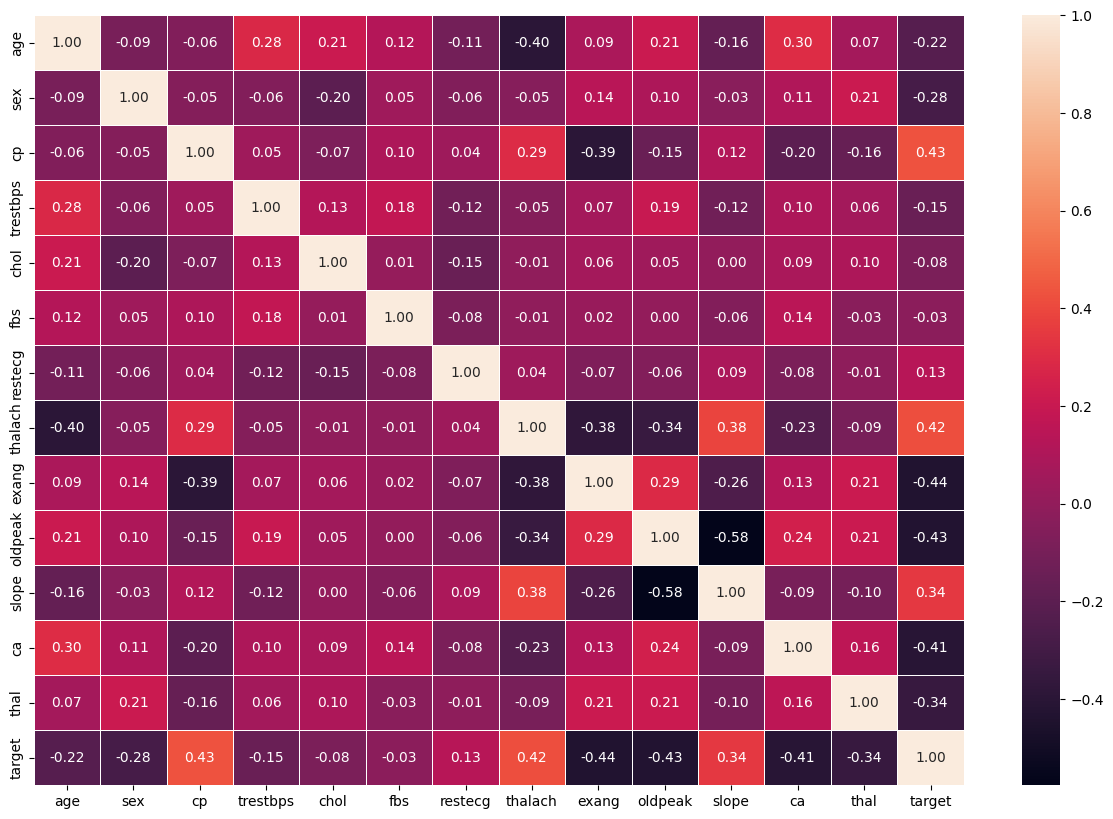

In [144]:
## Matriz de correlação
corr_matrix = df.corr()
fig,ax = plt.subplots(figsize = (15,10))
ax = sns.heatmap(corr_matrix, annot = True, linewidths = 0.5, fmt = ".2f")

In [145]:
## Valores da variável target 
df['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

In [146]:
## Percentual
countHaveDisease = len(df[df.target==1])
countNoDisease = len(df[df.target==0])
print("Percentual de Pacientes Com Doença: {:.2f}%".format((countHaveDisease / (len(df.target)) * 100)))
print("Percentual de Pacientes Sem Doença: {:.2f}%".format((countNoDisease / (len(df.target)) * 100)))

Percentual de Pacientes Com Doença: 54.30%
Percentual de Pacientes Sem Doença: 45.70%


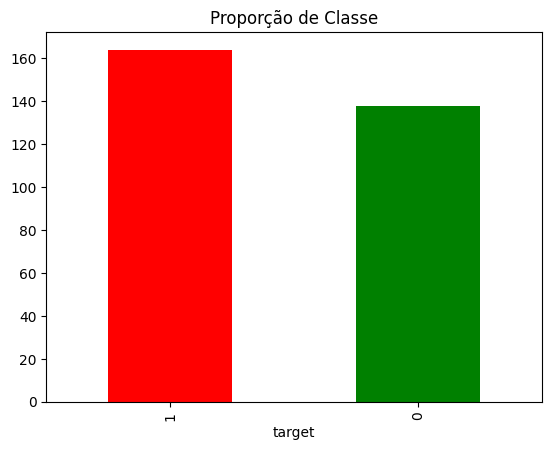

In [147]:
## Visualizando em gráficgraficamente
df['target'].value_counts().plot(kind = 'bar',
                                     color = ['red','green'],
                                     title = "Proporção de Classe");

In [148]:
## Variável de gênero
df['sex'].value_counts()

sex
1    206
0     96
Name: count, dtype: int64

In [149]:
## Tabela cruzada (Crosstab) entre gênero e variável target
pd.crosstab(df['target'], df['sex'])

sex,0,1
target,,
0,24,114
1,72,92


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

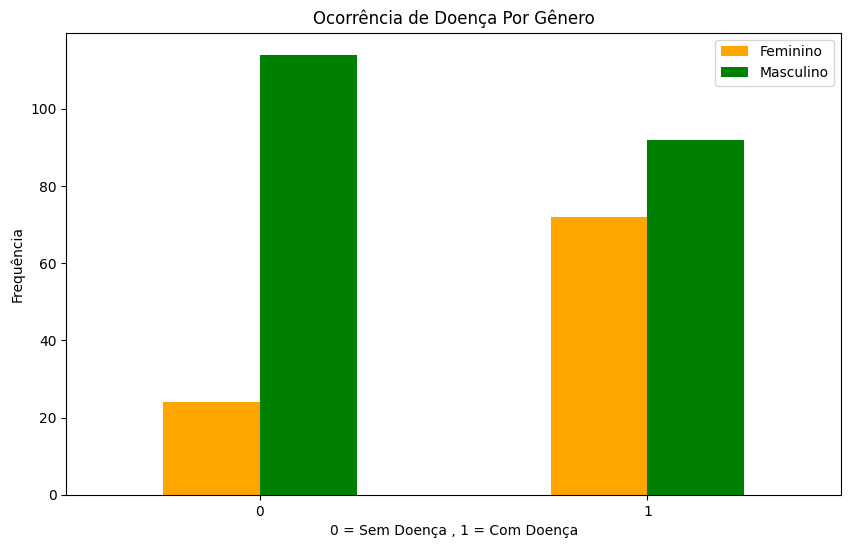

In [150]:
## Plot da Crosstab
pd.crosstab(df['target'], df['sex']).plot(kind = "bar", color = ["orange", "green"],  figsize = (10,6));
plt.title("Ocorrência de Doença Por Gênero")
plt.xlabel("0 = Sem Doença , 1 = Com Doença")
plt.ylabel("Frequência")
plt.legend(["Feminino", "Masculino"])
plt.xticks(rotation = 0)

In [151]:
## Relação da doença cardíaca com o tipo de dor torácica
pd.crosstab(df['cp'], df['target'])

target,0,1
cp,,
0,104,39
1,9,41
2,18,68
3,7,16


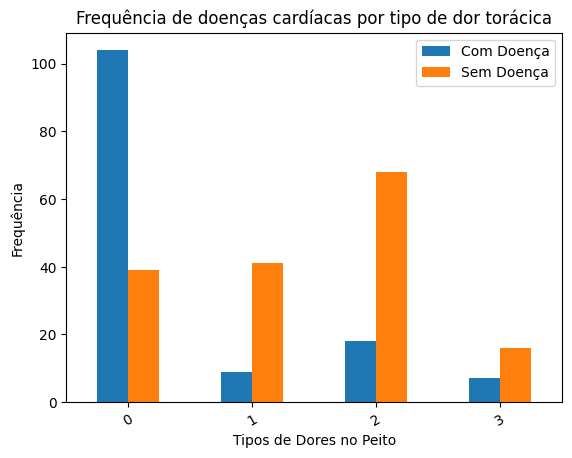

In [152]:
## Crosstab visual
pd.crosstab(df['cp'], df['target']).plot(kind = 'bar')
plt.title("Frequência de doenças cardíacas por tipo de dor torácica")
plt.xlabel("Tipos de Dores no Peito")
plt.ylabel("Frequência")
plt.legend(['Com Doença', 'Sem Doença'])
plt.xticks(rotation = 30);

In [153]:
## Contagem por categoria
df['fbs'].value_counts()

fbs
0    257
1     45
Name: count, dtype: int64

In [154]:
## Compara a coluna Alvo, ou seja, doença cardíaca com a coluna de açúcar no sangue em jejum
pd.crosstab(df['target'], df['fbs'])

fbs,0,1
target,,
0,116,22
1,141,23


(array([0, 1]), [Text(0, 0, '0'), Text(1, 0, '1')])

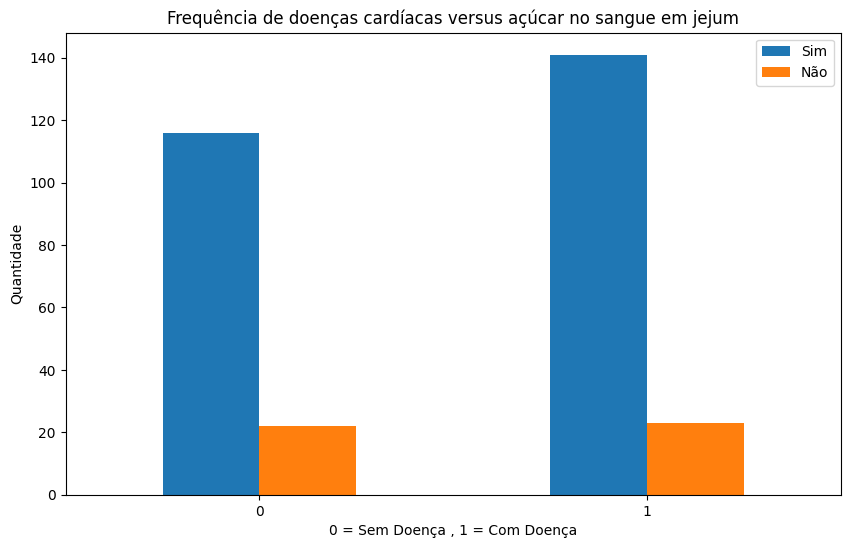

In [155]:
## Plot da crosstab
pd.crosstab(df['target'], df['fbs']).plot(kind = "bar",figsize = (10,6));
plt.title("Frequência de doenças cardíacas versus açúcar no sangue em jejum")
plt.xlabel("0 = Sem Doença , 1 = Com Doença")
plt.ylabel("Quantidade")
plt.legend(["Sim", "Não"])
plt.xticks(rotation = 0)

In [156]:
## Contagem de valores
df['restecg'].value_counts()

restecg
1    151
0    147
2      4
Name: count, dtype: int64

In [157]:
## Crosstab
pd.crosstab(df['target'], df['restecg'])

restecg,0,1,2
target,,,
0,79,56,3
1,68,95,1


In [158]:
## Contagem de valores
df['thal'].value_counts()

thal
2    165
3    117
1     18
0      2
Name: count, dtype: int64

In [159]:
## Crosstab
pd.crosstab(df['target'], df['thal'])

thal,0,1,2,3
target,,,,
0,1,12,36,89
1,1,6,129,28


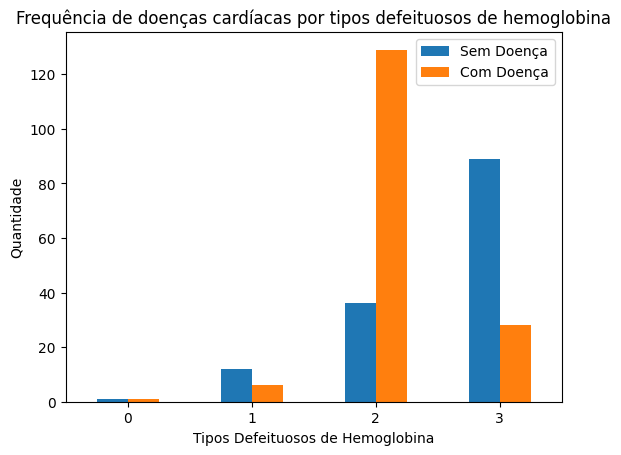

In [160]:
## Crosstab visual
pd.crosstab(df['thal'],df['target']).plot(kind = 'bar')
plt.title("Frequência de doenças cardíacas por tipos defeituosos de hemoglobina")
plt.xlabel("Tipos Defeituosos de Hemoglobina")
plt.ylabel("Quantidade")
plt.legend(['Sem Doença','Com Doença'])
plt.xticks(rotation = 0);

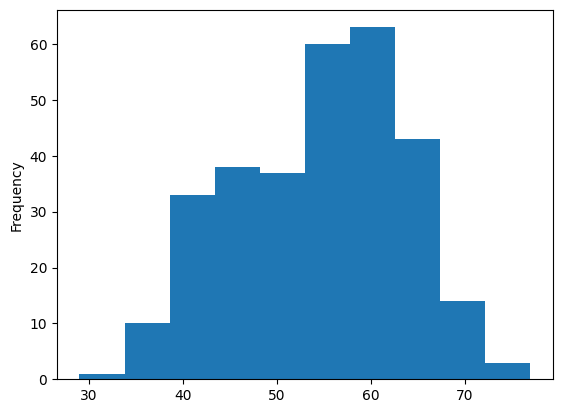

In [161]:
## Análise com Histograma e Scatterplot

## Verificando a distribuição da coluna de idade com um histograma
df['age'].plot(kind = 'hist');

In [162]:
## Verificando contagem de valores em frequência cardíaca máxima alcançada
df['thalach'].value_counts()

thalach
162    11
163     9
160     9
152     8
150     7
       ..
117     1
71      1
118     1
134     1
90      1
Name: count, Length: 91, dtype: int64

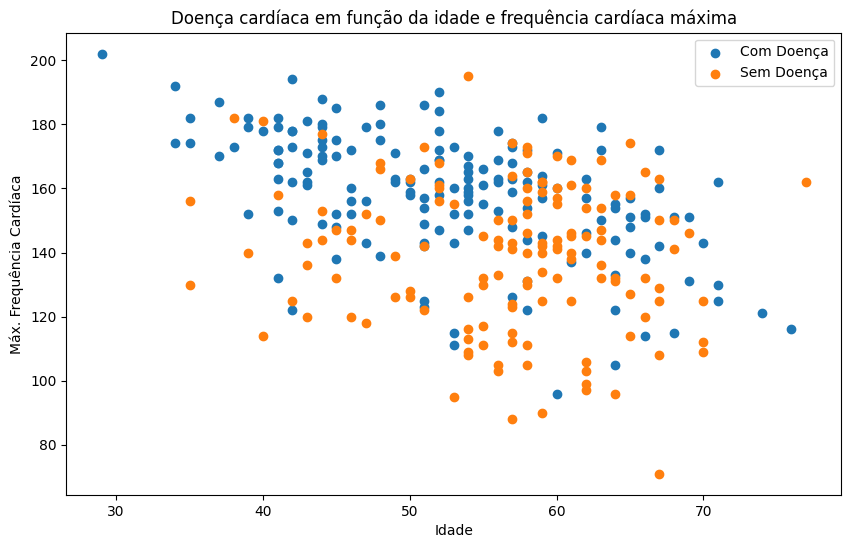

In [163]:
# Plot
plt.figure(figsize=(10,6))

# Target = 1
plt.scatter(x = df[df['target']==1]['age'], y = df.thalach[df.target==1])

# Target = 0
plt.scatter(x = df[df['target']==0]['age'], y = df.thalach[df.target==0],);

# Labels e título
plt.title("Doença cardíaca em função da idade e frequência cardíaca máxima")
plt.xlabel("Idade")
plt.ylabel("Máx. Frequência Cardíaca")
plt.legend(["Com Doença", "Sem Doença"])

Text(0.5, 1.0, 'Relação Tipos de Dor no Peito x Pressão Sanguinea x Gênero')

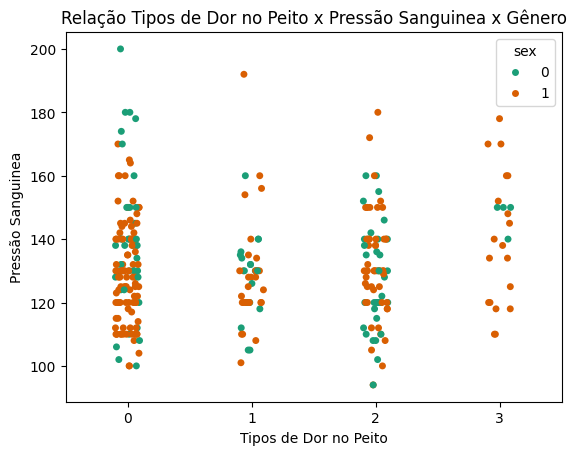

In [164]:
# Gráfico sobre a relação entre os tipos de dor no peito em repouso e a taxa de pressão com StripPlot
# arterial em relação ao gênero
sns.stripplot(x = "cp", y = "trestbps", hue = "sex", data = df, palette = "Dark2")
plt.xlabel('Tipos de Dor no Peito')
plt.ylabel('Pressão Sanguinea')
plt.title(label = "Relação Tipos de Dor no Peito x Pressão Sanguinea x Gênero", loc = 'center')

In [165]:
## Construção, treino e avaliação do modelo
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [166]:
## Preparando os dados para o modelo
X = df.drop('target', axis = 1)  # Variáveis independentes
y = df['target']  # Variável dependente

In [167]:
## Dividindo os dados em conjuntos de treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size = 0.2, random_state = 42)

In [168]:
## Criando o modelo XGBoost
modelo = XGBClassifier(n_estimators = 200,
                           learning_rate = 0.05,
                           max_depth = 3,
                           subsample = 0.8,
                           colsample_bytree = 0.8,
                           eval_metric = 'logloss',
                           random_state = 42)

In [169]:
## Treina o modelo (acompanhando a logloss nos dados de teste a cada rodada)
modelo.fit(X_treino, y_treino,
               eval_set = [(X_teste, y_teste)],
               verbose = False)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [170]:
## Previsões do modelo usando dados de teste
y_pred = modelo.predict(X_teste)

In [171]:
## Avaliando o modelo com dados de teste
accuracy = accuracy_score(y_teste, y_pred)
print("Acurácia:", accuracy)

Acurácia: 0.8688524590163934


In [172]:
## Extraindo a importância das características
feature_importances = modelo.feature_importances_
features = X.columns

In [173]:
## Criando um DataFrame para facilitar a visualização
importances_df = pd.DataFrame({'Variáveis': features, 'Importância': feature_importances})

In [174]:
## Ordenando as características pela importância
importances_df = importances_df.sort_values(by = 'Importância', ascending = False)

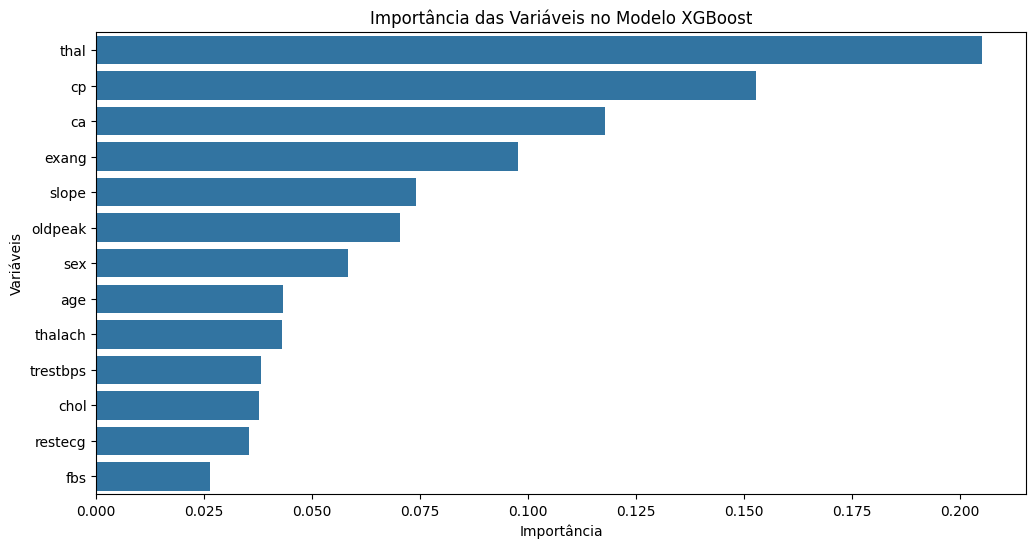

In [175]:
## Visualizando a importância das características
plt.figure(figsize = (12, 6))
sns.barplot(x = 'Importância', y = 'Variáveis', data = importances_df)
plt.title('Importância das Variáveis no Modelo XGBoost')
plt.xlabel('Importância')
plt.ylabel('Variáveis')
plt.show()

In [176]:
## Selecionando as 10 variáveis mais importantes
top_variables = importances_df['Variáveis'].head(10).tolist()

In [177]:
top_variables

['thal',
 'cp',
 'ca',
 'exang',
 'slope',
 'oldpeak',
 'sex',
 'age',
 'thalach',
 'trestbps']

In [178]:
## Preparando os dados com apenas as variáveis selecionadas
X_top = X[top_variables]

In [179]:
## Dividindo os dados em conjuntos de treino e teste
X_treino_top, X_teste_top, y_treino, y_teste = train_test_split(X_top, y, test_size = 0.2, random_state = 42)

In [180]:
# Criando e treinando um novo modelo XGBoost com as variáveis selecionadas
modelo_top = XGBClassifier(n_estimators = 200,
                               learning_rate = 0.05,
                               max_depth = 3,
                               subsample = 0.8,
                               colsample_bytree = 0.8,
                               eval_metric = 'logloss',
                               random_state = 42)

In [181]:
# Treino do modelo
modelo_top.fit(X_treino_top, y_treino,
                   eval_set = [(X_teste_top, y_teste)],
                   verbose = False)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


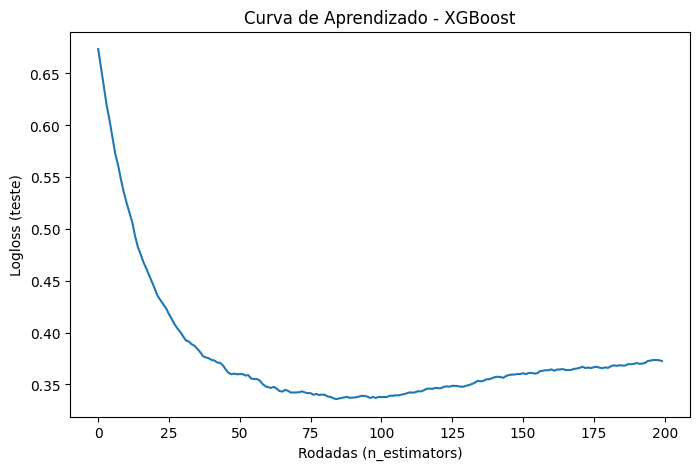

In [182]:
## Curva de aprendizado (logloss no conjunto de teste ao longo das rodadas de boosting)

resultados = modelo_top.evals_result()
plt.figure(figsize = (8, 5))
plt.plot(resultados['validation_0']['logloss'])
plt.title('Curva de Aprendizado - XGBoost')
plt.xlabel('Rodadas (n_estimators)')
plt.ylabel('Logloss (teste)')
plt.show()

In [183]:
## Avaliando o novo modelo
y_pred_top = modelo_top.predict(X_teste_top)
accuracy_top = accuracy_score(y_teste, y_pred_top)
print("Acurácia do Modelo com as 10 Variáveis Mais Relevantes:", accuracy_top)

Acurácia do Modelo com as 10 Variáveis Mais Relevantes: 0.8688524590163934


In [184]:
print(classification_report(y_teste, y_pred_top))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87        29
           1       0.90      0.84      0.87        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61



In [185]:
## Matriz de Confusão
confusion_matrix(y_teste, y_pred_top)

array([[26,  3],
       [ 5, 27]])

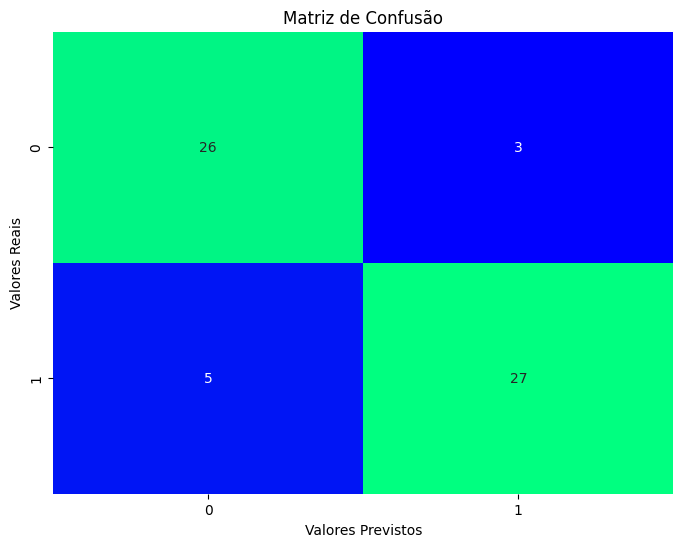

In [186]:
## Gerando a matriz de confusão
conf_matrix = confusion_matrix(y_teste, y_pred_top)

# Criando um gráfico para a matriz de confusão
plt.figure(figsize = (8, 6))
sns.heatmap(conf_matrix, annot = True, fmt = 'g', cmap = 'winter', cbar = False)
plt.title('Matriz de Confusão')
plt.xlabel('Valores Previstos')
plt.ylabel('Valores Reais')
plt.show()

In [187]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [188]:
top_variables

['thal',
 'cp',
 'ca',
 'exang',
 'slope',
 'oldpeak',
 'sex',
 'age',
 'thalach',
 'trestbps']

In [189]:
## Salvando o modelo treinado (formato nativo do XGBoost, mais estável entre versões que o joblib)
modelo_top.save_model('modelo_xgb.json')